# Phase 17 — Complete Corrected Model Comparison

**Project:** Australian Stock Market Analytics & Return Modeling

## Objective
Train all candidate regressors on the Phase 13 corrected, endpoint-audited training data, select a model using validation MAE, then evaluate every candidate on the exact same held-out test observations. Export predictions for every model so the comparison is reproducible.

**Important:** This notebook does not assume any model will beat the mean baseline. It uses the same corrected target and five candidate features for every model. It does not provide investment advice.

## 1. Setup and locate Phase 13 data

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 160)
RANDOM_STATE = 42

TRAIN_REL = Path("data/processed/model_features/asx_3m_strict_split_train.csv")
VALID_REL = Path("data/processed/model_features/asx_3m_strict_split_validation.csv")
TEST_REL = Path("data/processed/model_features/asx_3m_strict_split_test.csv")

def locate_root(start=Path.cwd()):
    for p in [start, *start.parents]:
        if all((p / r).exists() for r in [TRAIN_REL, VALID_REL, TEST_REL]):
            return p
    for p in start.iterdir() if start.exists() else []:
        if p.is_dir() and all((p / r).exists() for r in [TRAIN_REL, VALID_REL, TEST_REL]):
            return p
    return None

PROJECT_ROOT = locate_root()
if PROJECT_ROOT is None:
    raise FileNotFoundError("Could not locate all Phase 13 strict split CSVs. Run Phase 13 first.")

TRAIN_PATH, VALID_PATH, TEST_PATH = [PROJECT_ROOT / r for r in [TRAIN_REL, VALID_REL, TEST_REL]]
OUT = PROJECT_ROOT / "reports" / "complete_model_comparison"
PRED_OUT = PROJECT_ROOT / "data" / "processed" / "all_model_predictions"
OUT.mkdir(parents=True, exist_ok=True)
PRED_OUT.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)

Project root: e:\Projects\Australian Stock Market Data Science Project


## 2. Load and validate identical split structure

In [2]:
def read_split(path):
    df = pd.read_csv(path, low_memory=False)
    df.columns = [str(c).strip().lower() for c in df.columns]
    for c in ["date", "target_endpoint_date_3m"]:
        if c in df.columns:
            df[c] = pd.to_datetime(df[c], errors="coerce")
    df["ticker"] = df["ticker"].astype(str).str.strip().str.upper()
    df["forward_return_3m"] = pd.to_numeric(df["forward_return_3m"], errors="coerce")
    return df

train = read_split(TRAIN_PATH)
valid = read_split(VALID_PATH)
test = read_split(TEST_PATH)

required = {"ticker", "date", "target_endpoint_date_3m", "forward_return_3m"}
for label, part in [("train", train), ("validation", valid), ("test", test)]:
    missing = required - set(part.columns)
    if missing:
        raise ValueError(f"{label} missing required columns: {sorted(missing)}")
    if part[list(required)].isna().any().any():
        raise ValueError(f"{label} contains missing key/target values.")
    if part.duplicated(["ticker", "date"]).any():
        raise ValueError(f"{label} has duplicate ticker-date rows.")

if train.empty or valid.empty or test.empty:
    raise ValueError("At least one split is empty.")

assert train["target_endpoint_date_3m"].max() < valid["date"].min()
assert valid["target_endpoint_date_3m"].max() < test["date"].min()

print("Train/validation/test:", len(train), len(valid), len(test))
print("Train target endpoint max:", train["target_endpoint_date_3m"].max())
print("Validation start:", valid["date"].min())
print("Validation endpoint max:", valid["target_endpoint_date_3m"].max())
print("Test start:", test["date"].min())

Train/validation/test: 40447 6084 9412
Train target endpoint max: 2025-02-17 00:00:00
Validation start: 2025-02-18 00:00:00
Validation endpoint max: 2025-10-31 00:00:00
Test start: 2025-11-03 00:00:00


## 3. Define the common predictor set

All models use exactly the same available allowlisted features. Identifier columns, target columns, endpoint dates, and target endpoint prices are excluded.

In [3]:
candidate_features = [
    "momentum_21d",
    "momentum_63d",
    "benchmark_return_1d",
    "benchmark_volatility_21d",
    "benchmark_volatility_63d"
]
feature_cols = [c for c in candidate_features if c in train.columns]
if not feature_cols:
    raise ValueError("No candidate features were found in the Phase 13 split data.")

print("Features used:", feature_cols)
print("Features absent from split files:", sorted(set(candidate_features) - set(feature_cols)))

for part in [train, valid, test]:
    for col in feature_cols:
        part[col] = pd.to_numeric(part[col], errors="coerce").replace([np.inf, -np.inf], np.nan)

X_train, y_train = train[feature_cols], train["forward_return_3m"].astype(float)
X_valid, y_valid = valid[feature_cols], valid["forward_return_3m"].astype(float)
X_test, y_test = test[feature_cols], test["forward_return_3m"].astype(float)

Features used: ['momentum_21d', 'momentum_63d', 'benchmark_return_1d', 'benchmark_volatility_21d', 'benchmark_volatility_63d']
Features absent from split files: []


## 4. Define models

Preprocessing is fitted inside each pipeline. The mean baseline is a comparator, not a candidate we expect to outperform.

In [4]:
models = {
    "Training mean baseline": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", DummyRegressor(strategy="mean"))
    ]),
    "Linear Regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", LinearRegression())
    ]),
    "Ridge Regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", Ridge(alpha=10.0))
    ]),
    "Random Forest": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", RandomForestRegressor(
            n_estimators=300, min_samples_leaf=20, max_features=0.8,
            random_state=RANDOM_STATE, n_jobs=-1
        ))
    ]),
    "HistGradientBoosting": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", HistGradientBoostingRegressor(
            max_iter=150, learning_rate=0.05, max_leaf_nodes=15,
            l2_regularization=1.0, random_state=RANDOM_STATE
        ))
    ])
}

## 5. Train all models and compare validation metrics

Use validation MAE to select a non-baseline candidate. The test set remains untouched during model selection.

In [5]:
def metric_values(y_true, y_pred):
    return {
        "n": int(len(y_true)),
        "MAE": float(mean_absolute_error(y_true, y_pred)),
        "RMSE": float(np.sqrt(mean_squared_error(y_true, y_pred))),
        "R2": float(r2_score(y_true, y_pred)) if len(y_true) > 1 else np.nan,
        "actual_mean": float(np.mean(y_true)),
        "predicted_mean": float(np.mean(y_pred)),
        "mean_prediction_bias": float(np.mean(y_pred) - np.mean(y_true))
    }

fitted_models = {}
validation_predictions = {}
validation_rows = []

for name, model in models.items():
    model.fit(X_train, y_train)
    fitted_models[name] = model
    val_pred = model.predict(X_valid)
    validation_predictions[name] = val_pred
    validation_rows.append({"model": name, **metric_values(y_valid, val_pred)})

validation_results = pd.DataFrame(validation_rows).sort_values("MAE").reset_index(drop=True)
display(validation_results)
validation_results.to_csv(OUT / "validation_model_comparison.csv", index=False)

non_baseline = validation_results[
    validation_results["model"] != "Training mean baseline"
].copy()
best_candidate = str(non_baseline.sort_values("MAE").iloc[0]["model"]) if not non_baseline.empty else None
print("Best non-baseline by validation MAE:", best_candidate)

,model,n,MAE,RMSE,R2,actual_mean,predicted_mean,mean_prediction_bias
0,Training mean baseline,6084,0.141984,0.195113,-0.081749,0.075098,0.021461,-0.053637
1,HistGradientBoosting,6084,0.142511,0.198628,-0.121080,0.075098,0.027535,-0.047563
2,Random Forest,6084,0.146571,0.204790,-0.191712,0.075098,0.030853,-0.044245
3,Ridge Regression,6084,0.147386,0.202863,-0.169392,0.075098,0.011043,-0.064055
4,Linear Regression,6084,0.147392,0.202870,-0.169472,0.075098,0.011037,-0.064061


Best non-baseline by validation MAE: HistGradientBoosting


## 6. Evaluate every model on the same held-out test rows

All models are evaluated on the exact same `X_test` and `y_test`. This provides a valid apples-to-apples metric table. The test results are for final reporting only and should not be used to tune models repeatedly.

In [6]:
test_rows = []
test_prediction_table = test[["ticker", "date", "target_endpoint_date_3m", "forward_return_3m"]].copy()

for name, model in fitted_models.items():
    pred_values = model.predict(X_test)
    test_prediction_table["predicted__" + name.lower().replace(" ", "_")] = pred_values
    test_rows.append({"model": name, **metric_values(y_test, pred_values)})

test_results = pd.DataFrame(test_rows).sort_values("MAE").reset_index(drop=True)
display(test_results)
test_results.to_csv(OUT / "all_model_test_comparison.csv", index=False)
test_prediction_table.to_csv(PRED_OUT / "all_candidate_test_predictions.csv", index=False)

print("Saved all-model test predictions:", PRED_OUT / "all_candidate_test_predictions.csv")

,model,n,MAE,RMSE,R2,actual_mean,predicted_mean,mean_prediction_bias
0,Training mean baseline,9412,0.142559,0.183638,-0.030017,-0.009888,0.021461,0.031349
1,Ridge Regression,9412,0.144929,0.185742,-0.053759,-0.009888,0.021019,0.030907
2,Linear Regression,9412,0.144931,0.185745,-0.053785,-0.009888,0.021020,0.030908
3,HistGradientBoosting,9412,0.153697,0.198952,-0.208975,-0.009888,-0.011836,-0.001948
4,Random Forest,9412,0.156935,0.203337,-0.262853,-0.009888,-0.020755,-0.010867


Saved all-model test predictions: e:\Projects\Australian Stock Market Data Science Project\data\processed\all_model_predictions\all_candidate_test_predictions.csv


## 7. Compare every candidate with the mean baseline

Compute MAE improvement relative to the training-mean baseline. Positive values mean lower MAE than baseline; negative values mean worse MAE. Also compare RMSE and R².

,model,n,MAE,RMSE,R2,actual_mean,predicted_mean,mean_prediction_bias,MAE_improvement_vs_baseline_pct,RMSE_improvement_vs_baseline_pct,beats_baseline_MAE
0,Training mean baseline,9412,0.142559,0.183638,-0.030017,-0.009888,0.021461,0.031349,0.000000,0.000000,False
1,Ridge Regression,9412,0.144929,0.185742,-0.053759,-0.009888,0.021019,0.030907,-1.662696,-1.145914,False
2,Linear Regression,9412,0.144931,0.185745,-0.053785,-0.009888,0.021020,0.030908,-1.664168,-1.147162,False
3,HistGradientBoosting,9412,0.153697,0.198952,-0.208975,-0.009888,-0.011836,-0.001948,-7.812729,-8.339391,False
4,Random Forest,9412,0.156935,0.203337,-0.262853,-0.009888,-0.020755,-0.010867,-10.084162,-10.727164,False


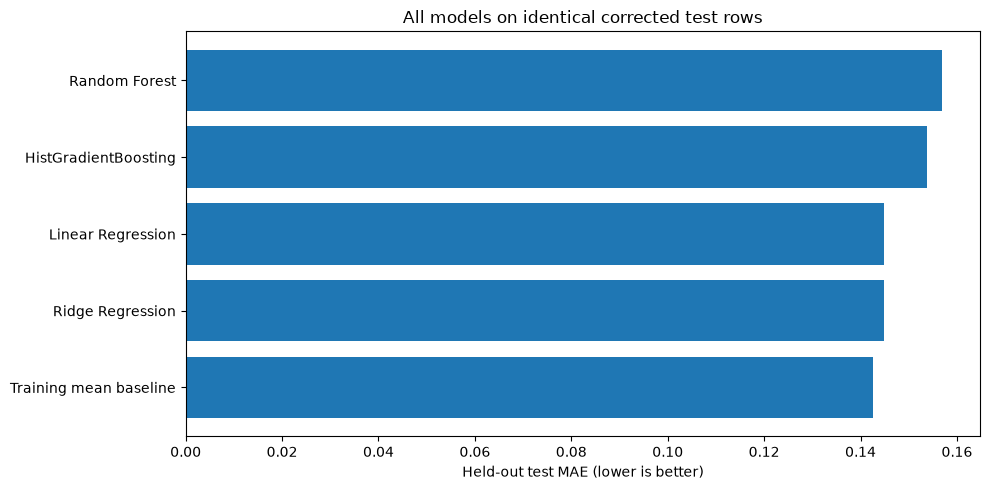

In [7]:
baseline_row = test_results[test_results["model"] == "Training mean baseline"].iloc[0]
comparison = test_results.copy()
comparison["MAE_improvement_vs_baseline_pct"] = 100 * (
    baseline_row["MAE"] - comparison["MAE"]
) / baseline_row["MAE"]
comparison["RMSE_improvement_vs_baseline_pct"] = 100 * (
    baseline_row["RMSE"] - comparison["RMSE"]
) / baseline_row["RMSE"]
comparison["beats_baseline_MAE"] = comparison["MAE"] < baseline_row["MAE"]
comparison = comparison.sort_values("MAE").reset_index(drop=True)
display(comparison)
comparison.to_csv(OUT / "baseline_relative_model_comparison.csv", index=False)

fig, ax = plt.subplots(figsize=(10, 5))
plot_df = comparison.sort_values("MAE")
ax.barh(plot_df["model"], plot_df["MAE"])
ax.set_xlabel("Held-out test MAE (lower is better)")
ax.set_title("All models on identical corrected test rows")
plt.tight_layout()
plt.savefig(OUT / "all_model_test_mae.png", dpi=150, bbox_inches="tight")
plt.show()

## 8. Select final model by validation only and summarize test result

Final model selection is based on validation MAE among non-baseline models. If the baseline has the lowest validation MAE, report that the experiment did not establish an improvement from the candidate ML models. Do not select a model solely because it has the best test score.

In [8]:
baseline_val_mae = float(validation_results.loc[
    validation_results["model"] == "Training mean baseline", "MAE"
].iloc[0])
best_candidate_val_mae = float(validation_results.loc[
    validation_results["model"] == best_candidate, "MAE"
].iloc[0]) if best_candidate else np.nan

if best_candidate and best_candidate_val_mae < baseline_val_mae:
    final_selection = best_candidate
    selection_note = "Best non-baseline model beat the baseline on validation MAE."
else:
    final_selection = "Training mean baseline"
    selection_note = "No non-baseline model beat the baseline on validation MAE."

final_test_row = test_results[test_results["model"] == final_selection].iloc[0].to_dict()
baseline_test_row = test_results[test_results["model"] == "Training mean baseline"].iloc[0].to_dict()

summary = {
    "phase": 17,
    "target": "forward_return_3m",
    "features": feature_cols,
    "train_rows": int(len(train)),
    "validation_rows": int(len(valid)),
    "test_rows": int(len(test)),
    "models_compared": list(models.keys()),
    "best_non_baseline_by_validation_mae": best_candidate,
    "baseline_validation_mae": baseline_val_mae,
    "best_candidate_validation_mae": best_candidate_val_mae,
    "final_selection": final_selection,
    "selection_note": selection_note,
    "final_selection_test_metrics": final_test_row,
    "baseline_test_metrics": baseline_test_row,
    "beats_baseline_test_mae": bool(final_test_row["MAE"] < baseline_test_row["MAE"]),
    "warning": "A model score does not establish profitability. This is an educational historical experiment, not investment advice."
}
with open(OUT / "phase17_complete_model_comparison_summary.json", "w", encoding="utf-8") as f:
    json.dump(summary, f, indent=2, default=str)

report = [
    "# Phase 17 — Complete Model Comparison",
    "",
    f"- Final selection based on validation: **{final_selection}**",
    f"- Reason: {selection_note}",
    f"- Test observations: {len(test):,}",
    f"- Test MAE: {final_test_row['MAE']:.6f}",
    f"- Test RMSE: {final_test_row['RMSE']:.6f}",
    f"- Test R²: {final_test_row['R2']:.6f}",
    f"- Baseline test MAE: {baseline_test_row['MAE']:.6f}",
    f"- Beats baseline test MAE: {summary['beats_baseline_test_mae']}",
    "",
    "## Test comparison",
    test_results.to_string(index=False),
    "",
    "## Limitations",
    "- The target is a 63-observation forward return, not necessarily exactly three calendar months.",
    "- Predictor allowlisting reduces but does not eliminate the need to verify point-in-time feature construction.",
    "- A lower MAE does not prove that a trading strategy is profitable after transaction costs and other constraints.",
    "- All conclusions apply to this historical held-out period only."
]
report_path = OUT / "phase17_complete_model_comparison_report.md"
report_path.write_text("\n".join(report), encoding="utf-8")

print(json.dumps(summary, indent=2, default=str))
print("\nReport saved:", report_path)
print("All outputs saved to:", OUT)

{
  "phase": 17,
  "target": "forward_return_3m",
  "features": [
    "momentum_21d",
    "momentum_63d",
    "benchmark_return_1d",
    "benchmark_volatility_21d",
    "benchmark_volatility_63d"
  ],
  "train_rows": 40447,
  "validation_rows": 6084,
  "test_rows": 9412,
  "models_compared": [
    "Training mean baseline",
    "Linear Regression",
    "Ridge Regression",
    "Random Forest",
    "HistGradientBoosting"
  ],
  "best_non_baseline_by_validation_mae": "HistGradientBoosting",
  "baseline_validation_mae": 0.14198443955103976,
  "best_candidate_validation_mae": 0.14251056889815858,
  "final_selection": "Training mean baseline",
  "selection_note": "No non-baseline model beat the baseline on validation MAE.",
  "final_selection_test_metrics": {
    "model": "Training mean baseline",
    "n": 9412,
    "MAE": 0.14255885547150116,
    "RMSE": 0.18363815182311155,
    "R2": -0.030017160524183906,
    "actual_mean": -0.009887806217044012,
    "predicted_mean": 0.021461323363067605,

## 9. Completion checklist

- Confirm all five models were trained and evaluated on the same corrected splits.
- Review `validation_model_comparison.csv` for validation-only model selection.
- Review `all_model_test_comparison.csv` and `baseline_relative_model_comparison.csv`.
- Inspect the exported all-model prediction file.
- Report results honestly even if the baseline remains the best choice.